# Ensembles: stacking, voting, CatBoost — Code-Along Template

**Type into this notebook during class.** The explanation is here; the code is not.

| | |
|---|---|
| **Follow along** | Write the code in each `# TODO` cell. The hint names the functions and arguments. |
| **If you fall behind** | Do not copy frantically. Skip to the next **CHECKPOINT**, run it, rejoin. |
| **If a cell errors** | Later cells depend on it and will fail too. Run the next CHECKPOINT rather than debugging under time pressure. |
| **After class** | The worked version is `D012_catboost.ipynb`. Compare, do not copy. |

Cells that are already filled in are deliberate — imports and quick glances at the
data cost class time and teach nothing.

In [55]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from catboost import CatBoostClassifier
from sklearn.metrics import classification_report,ConfusionMatrixDisplay

In [ ]:
# TODO: compute `df`
# Name your result: df

In [57]:
df.columns

Index(['Unnamed: 0', 'patient_id', 'age', 'gender', 'blood_pressure_systolic',
       'heart_rate', 'bmi', 'num_prior_admissions', 'length_of_stay_days',
       'admission_date', 'discharge_date', 'department', 'diagnosis_category',
       'severity', 'insurance_type', 'clinical_notes', 'medication_count',
       'lab_result_glucose', 'lab_result_creatinine', 'is_emergency',
       'random_noise', 'readmitted_within_30_days'],
      dtype='object')

In [ ]:
# TODO: compute `X`, `y` from `readmitted_within_30_days`
# Name your result: X, y

In [ ]:
# TODO: compute `num_feat`, `cat_feat`
# Name your result: num_feat, cat_feat

In [ ]:
# TODO: compute `num_trans`, `cat_trans`, `preprocessor`
# Name your result: num_trans, cat_trans, preprocessor

In [ ]:
# TODO: write the code for this step
# Name your result: cat_indices

In [ ]:
# TODO: compute `cat_pipeline`
# Name your result: cat_pipeline

In [ ]:
# TODO: call `train_test_split`

In [64]:
# from imblearn.over_sampling import RandomOverSampler, SMOTE

In [65]:
# smote = SMOTE()
# X_train_res ,y_train_res = smote.fit_resample(X_train,y_train)

In [66]:
cat_pipeline.fit(X_train,y_train)

Learning rate set to 0.03366
0:	learn: 0.5676207	total: 8.38ms	remaining: 8.37s
1:	learn: 0.4741243	total: 15.1ms	remaining: 7.54s
2:	learn: 0.3856935	total: 22.5ms	remaining: 7.48s
3:	learn: 0.3232749	total: 31.6ms	remaining: 7.86s
4:	learn: 0.2611017	total: 38.3ms	remaining: 7.63s
5:	learn: 0.2055094	total: 43.3ms	remaining: 7.17s
6:	learn: 0.1693535	total: 49ms	remaining: 6.95s
7:	learn: 0.1445025	total: 55.7ms	remaining: 6.9s
8:	learn: 0.1204926	total: 63.4ms	remaining: 6.98s
9:	learn: 0.1007747	total: 69.5ms	remaining: 6.88s
10:	learn: 0.0841957	total: 76.7ms	remaining: 6.89s
11:	learn: 0.0674150	total: 80.7ms	remaining: 6.64s
12:	learn: 0.0552604	total: 87.6ms	remaining: 6.65s
13:	learn: 0.0450809	total: 92.6ms	remaining: 6.52s
14:	learn: 0.0379375	total: 103ms	remaining: 6.78s
15:	learn: 0.0324657	total: 110ms	remaining: 6.76s
16:	learn: 0.0284513	total: 117ms	remaining: 6.76s
17:	learn: 0.0244960	total: 124ms	remaining: 6.75s
18:	learn: 0.0209321	total: 131ms	remaining: 6.74s
1

,steps,"[('preprocessor', ...), ('cat', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [ ]:
# TODO: compute `y_pred`
# Name your result: y_pred

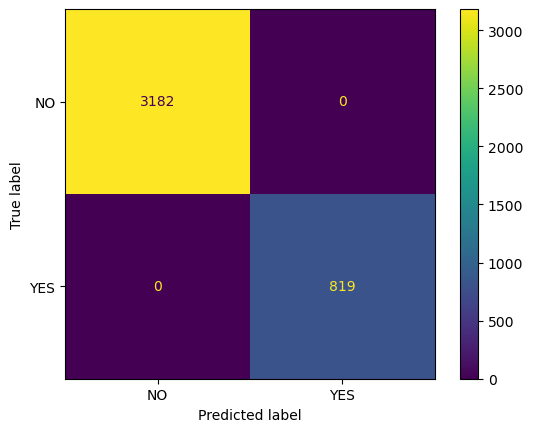

In [68]:
ConfusionMatrixDisplay.from_predictions(y_test,y_pred,display_labels=['NO','YES'])

In [69]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      3182
           1       1.00      1.00      1.00       819

    accuracy                           1.00      4001
   macro avg       1.00      1.00      1.00      4001
weighted avg       1.00      1.00      1.00      4001



In [72]:
model = cat_pipeline.named_steps['cat']
# model.get_best_iteration
importance = model.get_feature_importance()
# importance

In [ ]:
# TODO: call `.head()`

In [ ]:
df.columns

In [ ]:
# TODO: compute `ct` from `insurance_type`, `readmitted_within_30_days`
# Name your result: ct

In [38]:
insurance_cat = CatBoostClassifier(
    cat_features=[0]
)

In [39]:
insurance_cat.fit(X_train[['insurance_type']],y_train)

Learning rate set to 0.03366
0:	learn: 0.6799139	total: 8.72ms	remaining: 8.71s
1:	learn: 0.6676172	total: 13.5ms	remaining: 6.73s
2:	learn: 0.6562009	total: 18.2ms	remaining: 6.04s
3:	learn: 0.6455994	total: 23.4ms	remaining: 5.82s
4:	learn: 0.6357554	total: 32.5ms	remaining: 6.46s
5:	learn: 0.6266155	total: 36.9ms	remaining: 6.11s
6:	learn: 0.6181298	total: 42.5ms	remaining: 6.03s
7:	learn: 0.6102478	total: 47.7ms	remaining: 5.91s
8:	learn: 0.6029319	total: 52.6ms	remaining: 5.79s
9:	learn: 0.5961419	total: 58.6ms	remaining: 5.8s
10:	learn: 0.5898381	total: 61ms	remaining: 5.49s
11:	learn: 0.5839815	total: 66ms	remaining: 5.43s
12:	learn: 0.5785476	total: 74.8ms	remaining: 5.68s
13:	learn: 0.5735023	total: 83.5ms	remaining: 5.88s
14:	learn: 0.5688173	total: 88.4ms	remaining: 5.81s
15:	learn: 0.5644666	total: 91.7ms	remaining: 5.64s
16:	learn: 0.5604244	total: 105ms	remaining: 6.08s
17:	learn: 0.5566718	total: 109ms	remaining: 5.94s
18:	learn: 0.5531861	total: 112ms	remaining: 5.8s
19

CatBoostClassifier(cat_features=[0])

In [40]:
y_pred = insurance_cat.predict(X_test[['insurance_type']])
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.80      1.00      0.89      3182
           1       0.00      0.00      0.00       819

    accuracy                           0.80      4001
   macro avg       0.40      0.50      0.44      4001
weighted avg       0.63      0.80      0.70      4001



/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/opt/anaconda3/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [74]:
df.columns

Index(['Unnamed: 0', 'patient_id', 'age', 'gender', 'blood_pressure_systolic',
       'heart_rate', 'bmi', 'num_prior_admissions', 'length_of_stay_days',
       'admission_date', 'discharge_date', 'department', 'diagnosis_category',
       'severity', 'insurance_type', 'clinical_notes', 'medication_count',
       'lab_result_glucose', 'lab_result_creatinine', 'is_emergency',
       'random_noise', 'readmitted_within_30_days'],
      dtype='object')

In [75]:
df.groupby('readmitted_within_30_days')['medication_count'].describe()

,count,mean,std,min,25%,50%,75%,max
readmitted_within_30_days,,,,,,,,
0,15909.0,10.473631,5.747802,1.0,5.0,10.0,15.0,20.0
1,4094.0,10.517831,5.806855,1.0,5.0,11.0,16.0,20.0


In [78]:
import matplotlib.pyplot as plt

In [ ]:
# TODO: draw a `plt.subplots` of `medication_count`